<a href="https://colab.research.google.com/github/whoseei/ANASISI-REGRESI-BERGANDA/blob/main/Regresi_Berganda_Musda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Latihan Regresi Linear Berganda (Data Panel)

Y (terikat) = KEMISKINAN

X (bebas) = bm_perlindungan_sosial & PAD


In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

## Baca data

In [33]:
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)
df.columns = df.columns.str.strip()

daftar_kota = ['Kota Banda Aceh', 'Kota Medan']
df = df[df['Kota'].isin(daftar_kota)].copy()
df

,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
0,Kota Banda Aceh,2014,77.91,49.42,26.00,96.98,47.59,83.94,72.02,153.66,...,175.78,253.43,286.18,100.88,133.54,5.31,9.79,0.47,65.31,2.82
1,Kota Banda Aceh,2015,54.88,37.29,35.35,112.77,59.88,74.74,52.84,119.84,...,98.47,285.13,133.72,268.34,254.48,10.50,6.19,0.46,64.99,7.33
2,Kota Banda Aceh,2016,78.91,27.08,39.83,107.56,52.78,96.58,97.41,179.24,...,264.70,212.19,192.71,64.94,59.59,9.57,3.68,0.44,71.00,4.82
3,Kota Banda Aceh,2017,72.77,26.01,46.46,109.93,80.91,63.84,73.98,150.55,...,219.24,288.64,277.40,272.15,267.70,7.77,9.79,0.46,83.49,7.27
4,Kota Banda Aceh,2018,93.06,82.81,31.70,127.89,60.87,77.19,80.88,148.09,...,259.48,87.86,51.55,132.27,178.19,17.43,5.50,0.36,73.57,5.52
5,Kota Banda Aceh,2019,92.60,29.52,51.04,142.44,61.59,51.67,93.28,175.40,...,264.69,169.35,252.67,128.65,149.56,15.94,8.40,0.31,68.96,6.05
6,Kota Banda Aceh,2020,97.36,58.70,34.77,107.83,68.51,69.25,90.38,171.14,...,237.09,200.45,287.09,178.02,174.29,18.31,6.31,0.32,77.83,6.83
7,Kota Banda Aceh,2021,102.50,83.44,49.04,165.62,93.72,67.32,72.74,135.43,...,159.80,195.43,72.83,285.17,216.85,14.55,5.20,0.40,82.69,5.95
8,Kota Banda Aceh,2022,81.18,72.27,35.37,119.55,74.24,66.84,111.08,208.16,...,202.64,150.37,90.36,61.95,53.19,14.50,9.10,0.46,64.66,4.39
9,Kota Banda Aceh,2023,115.08,97.74,70.87,173.29,82.99,91.80,106.69,271.82,...,90.09,134.52,290.19,138.06,267.89,17.91,3.05,0.40,70.44,5.08


## Cek struktur data panel

In [48]:
# data panel = banyak kota (cross section) x banyak tahun (time series)
print("jumlah kota :", df['Kota'].nunique())
print("jumlah tahun:", df['Tahun'].nunique())
print("jumlah baris:", len(df))

# kalau balanced, tiap kota punya jumlah tahun yang sama
df.groupby('Kota')['Tahun'].count().value_counts()

jumlah kota : 2
jumlah tahun: 11
jumlah baris: 22


,count
Tahun,
11,2


## Ambil variabel

In [49]:
kolom = ['Kota', 'Tahun', 'KEMISKINAN', 'bm_perlindungan_sosial','PAD']
data = df[kolom].copy()

data.describe()

,Tahun,KEMISKINAN,bm_perlindungan_sosial,PAD
count,22.000000,22.000000,22.000000,22.000000
mean,2019.000000,12.275455,165.388182,252.478182
std,3.236694,4.362620,74.835858,98.846718
min,2014.000000,5.310000,53.190000,119.840000
25%,2016.250000,8.685000,106.862500,172.205000
50%,2019.000000,11.795000,156.420000,241.675000
75%,2021.750000,15.810000,223.202500,313.315000
max,2024.000000,19.440000,297.300000,453.690000


## Korelasi antar variabel

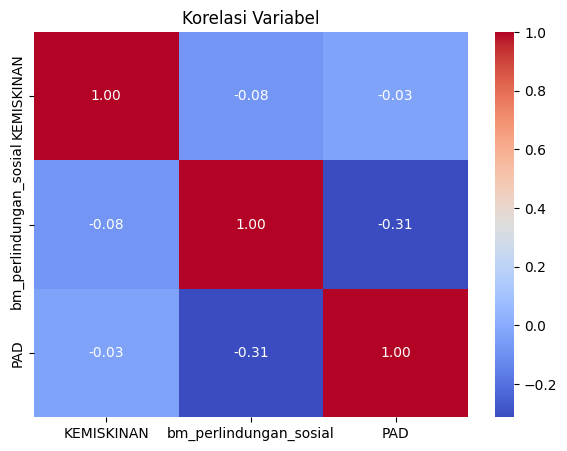

In [50]:
plt.figure(figsize=(7, 5))
sns.heatmap(data.drop(columns=['Kota', 'Tahun']).corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Variabel')
plt.show()

## Model 1: Regresi berganda biasa (Pooled OLS)

In [53]:
# rumus: Y ~ X1 + X2 + X3 + X4
model1 = smf.ols('KEMISKINAN ~ bm_perlindungan_sosial + PAD', data=data).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.011
Model:                            OLS   Adj. R-squared:                 -0.093
Method:                 Least Squares   F-statistic:                    0.1033
Date:                Mon, 12 Oct 2026   Prob (F-statistic):              0.902
Time:                        13:23:35   Log-Likelihood:                -62.994
No. Observations:                  22   AIC:                             132.0
Df Residuals:                      19   BIC:                             135.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 14

In [54]:
print("R-squared     :", round(model1.rsquared, 4))
print("Adj R-squared :", round(model1.rsquared_adj, 4))
print("Prob F        :", model1.f_pvalue)

# tabel ringkas koefisien dan p-value
hasil1 = pd.DataFrame({'koefisien': model1.params, 'p_value': model1.pvalues})
hasil1['signifikan'] = np.where(hasil1['p_value'] < 0.05, 'ya', 'tidak')
hasil1.round(4)

R-squared     : 0.0108
Adj R-squared : -0.0934
Prob F        : 0.9023776000499242


,koefisien,p_value,signifikan
Intercept,14.0148,0.0033,ya
bm_perlindungan_sosial,-0.0060,0.6735,tidak
PAD,-0.0030,0.7830,tidak


## Cek multikolinearitas (VIF)

In [56]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X = data[['bm_perlindungan_sosial', 'PAD']]
X = add_constant(X)

# VIF > 10 artinya ada multikolinearitas
vif = pd.DataFrame({'variabel': X.columns,
                    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif[vif['variabel'] != 'const'].round(3)

,variabel,VIF
1,bm_perlindungan_sosial,1.109
2,PAD,1.109


## Model 2: Fixed Effect (tambah dummy Kota)

In [57]:
# C(Kota) = dummy tiap kota, jadi tiap kota punya intersep sendiri
model2 = smf.ols('KEMISKINAN ~ bm_perlindungan_sosial + PAD + C(Kota)', data=data).fit()

# dummy kota ada banyak sekali, jadi yang ditampilkan hanya variabel X
hasil2 = pd.DataFrame({'koefisien': model2.params, 'p_value': model2.pvalues})
hasil2 = hasil2[~hasil2.index.str.startswith('C(')]

print("R-squared     :", round(model2.rsquared, 4))
print("Adj R-squared :", round(model2.rsquared_adj, 4))
hasil2.round(4)

R-squared     : 0.2589
Adj R-squared : 0.1354


,koefisien,p_value
Intercept,8.9830,0.0480
bm_perlindungan_sosial,0.0004,0.9734
PAD,0.0265,0.0998


## Bandingkan kedua model

In [58]:
perbandingan = pd.DataFrame({
    'Model': ['Pooled OLS', 'Fixed Effect'],
    'R-squared': [model1.rsquared, model2.rsquared],
    'Adj R-squared': [model1.rsquared_adj, model2.rsquared_adj],
    'AIC': [model1.aic, model2.aic]
})
perbandingan.round(4)

,Model,R-squared,Adj R-squared,AIC
0,Pooled OLS,0.0108,-0.0934,131.9872
1,Fixed Effect,0.2589,0.1354,127.6340


## Grafik

### Grafik 3D Regresi

In [62]:
import plotly.graph_objects as go
import numpy as np

# 1. Menyiapkan variabel untuk grafik 3D
x1 = data['bm_perlindungan_sosial']
x2 = data['PAD']
y = data['KEMISKINAN']

# 2. Membuat grid untuk bidang permukaan regresi
x1_range = np.linspace(x1.min(), x1.max(), 30)
x2_range = np.linspace(x2.min(), x2.max(), 30)
X1_grid, X2_grid = np.meshgrid(x1_range, x2_range)

# Menghitung nilai Z (prediksi Y) berdasarkan Model 1 (Pooled OLS)
Y_grid = model1.params['Intercept'] + model1.params['bm_perlindungan_sosial'] * X1_grid + model1.params['PAD'] * X2_grid

# 3. Membuat figure Plotly
fig = go.Figure()

# Menambahkan titik data aktual (Scatter 3D)
fig.add_trace(go.Scatter3d(
    x=x1, y=x2, z=y,
    mode='markers',
    marker=dict(size=6, color='red', opacity=0.9),
    name='Data Aktual',
    text=[f"Kota: {k}, Tahun: {t}" for k, t in zip(data['Kota'], data['Tahun'])],
    hovertemplate="<b>%{text}</b><br>BM Perlindungan Sosial: %{x}<br>PAD: %{y}<br>Kemiskinan: %{z}<extra></extra>"
))

# Menambahkan bidang permukaan regresi (Surface)
fig.add_trace(go.Surface(
    x=X1_grid, y=X2_grid, z=Y_grid,
    opacity=0.6,
    colorscale='Viridis',
    name='Bidang Regresi',
    hovertemplate="BM Perlindungan Sosial: %{x:.2f}<br>PAD: %{y:.2f}<br>Prediksi Kemiskinan: %{z:.2f}<extra></extra>"
))

# 4. Mengatur Tampilan Layout Grafik
persamaan = f"Y = {model1.params['Intercept']:.3f} + ({model1.params['bm_perlindungan_sosial']:.3f})X1 + ({model1.params['PAD']:.3f})X2"
fig.update_layout(
    title={
        "text": f"REGRESI LINEAR BERGANDA 3D – BANDA ACEH & MEDAN<br><sup>{persamaan} | R² = {model1.rsquared:.3f}</sup>",
        "x": 0.5
    },
    scene={
        "xaxis": {"title": "BM Perlindungan Sosial (X₁)"},
        "yaxis": {"title": "PAD (X₂)"},
        "zaxis": {"title": "Kemiskinan (Y)"}
    },
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 100},
    legend={"x": 0.02, "y": 0.98}
)

# 5. Menampilkan grafik interaktif
fig.show()
fig.write_html("grafik_regresi_3d.html")

### Nilai aktual vs prediksi

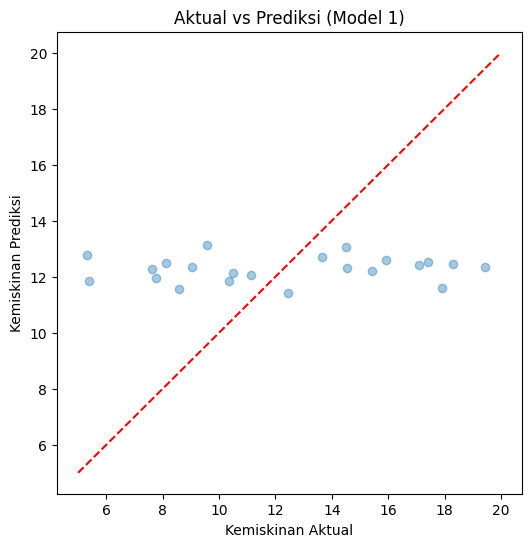

In [60]:
plt.figure(figsize=(6, 6))
plt.scatter(data['KEMISKINAN'], model1.fittedvalues, alpha=0.4)

# garis y = x (kalau pas, titik ada di garis ini)
plt.plot([5, 20], [5, 20], color='red', linestyle='--')

plt.title('Aktual vs Prediksi (Model 1)')
plt.xlabel('Kemiskinan Aktual')
plt.ylabel('Kemiskinan Prediksi')
plt.show()

### Sebaran residual

> Tambahkan blockquote



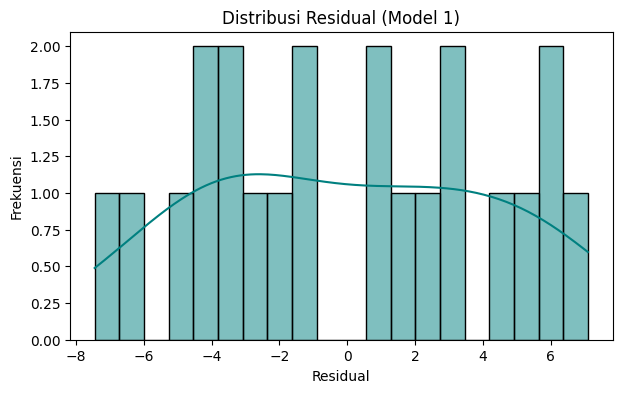

In [61]:
plt.figure(figsize=(7, 4))
sns.histplot(model1.resid, bins=20, kde=True, color='teal')

plt.title('Distribusi Residual (Model 1)')
plt.xlabel('Residual')
plt.ylabel('Frekuensi')
plt.show()

## Kesimpulan

1. Variabel Signifikan: Variabel bebas (bm_perlindungan_sosial dan PAD) tidak berpengaruh signifikan secara statistik terhadap kemiskinan pada taraf nyata 5% (p > 0.05).
2. Nilai R-squared: R-squared Pooled OLS sebesar 0.011 (1.1%) dan Fixed Effect sebesar 0.259 (25.9%), yang menunjukkan bahwa kemampuan variabel independen dalam menjelaskan tingkat kemiskinan tergolong rendah dan lebih banyak dipengaruhi oleh faktor lain di luar model.
3. Uji Multikolinearitas (VIF): Aman. Seluruh nilai VIF berada di kisaran 1.109 (jauh di bawah 10), sehingga tidak ada masalah multikolinearitas antar variabel bebas.
4. Perbandingan Model: Berdasarkan nilai AIC, model Fixed Effect (AIC: 127.63) lebih baik dibanding Pooled OLS (AIC: 131.99) karena penambahan efek antar kota mampu menaikkan nilai R-squared menjadi 25.9%.
